# Build gates and recover an interference pattern

In the previous notebook you prepared a two-entry amplitude vector and changed the measurement basis. Now you will calculate how **gates** change that state, check that the transformations are reversible, and build a circuit that converts relative phase into a measurable probability.

**Conventions:** the basis order is `[|0⟩, |1⟩]`, and states are column vectors even though NumPy displays a one-dimensional array. A gate is a complex `2 × 2` matrix. `U @ ψ` means apply gate `U` to state `ψ`; in `B @ A @ ψ`, the rightmost gate `A` acts first. Every angle in the code is in radians.

**Model boundary:** ideal single-qubit gates with no device noise or decoherence. We compare a coherent pure state with an explicitly defined classical ensemble. This is not a hardware-speedup experiment or a model of every quantum system.

**Reproduce locally:** install `notebooks/requirements.txt` with Python 3.10 or newer, open the downloaded notebook in Jupyter, and **Restart Kernel and Run All**. Website outputs are saved from a successful run; Python does not execute in the page.

## 1. Prepare the numerical workspace

Use the same normalized-state validator as the state notebook. The imaginary unit is `1j`; `np.vdot(ψ, ψ)` is a state's norm squared. The validator catches a bad state instead of normalizing it silently.

**Reproducible sampling:** a seeded **PCG64** bit generator produces a fixed stream of unsigned 64-bit integers. We take the upper 53 bits and divide by `2**53` to obtain uniform numbers in `[0, 1)`. This fixed conversion avoids version-dependent algorithms in convenience methods such as `binomial` or `multinomial`. A binary result uses `uniform < p`; a multi-outcome result uses the cumulative probabilities. These simulate independent ideal trials; they do not model physical random-number hardware.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.2, 3.8), "figure.dpi": 120,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#24354b", "text.color": "#24354b",
    "xtick.color": "#44556c", "ytick.color": "#44556c",
    "font.size": 11, "axes.titleweight": "bold",
    "axes.grid": True, "grid.alpha": 0.16,
    "grid.color": "#718198", "lines.linewidth": 2.4,
    "savefig.bbox": "tight",
})
BLUE, GREEN, AMBER = "#3c6db3", "#27836d", "#b87920"
TOLERANCE = 1e-10


def assert_state(state):
    state = np.asarray(state, dtype=complex)
    if state.shape not in ((2,), (4,)):
        raise ValueError("This model supports one or two qubits.")
    if not np.isfinite(state).all():
        raise ValueError("All amplitudes must be finite.")
    if not np.isclose(np.vdot(state, state).real, 1, atol=TOLERANCE, rtol=0):
        raise ValueError("The state must already be normalized.")
    return state


def probabilities(state):
    return np.abs(assert_state(state)) ** 2


print(f"Ready: NumPy {np.__version__}, Matplotlib {matplotlib.__version__}")
print("Ideal finite-dimensional model; every plot is computed by this notebook.")



def uniform_samples(generator, shape):
    raw = generator.bit_generator.random_raw(shape)
    return (raw >> np.uint64(11)).astype(np.float64) * (1.0 / 2**53)


def sample_outcomes(distribution, generator, shots):
    distribution = np.asarray(distribution, dtype=np.float64)
    if distribution.ndim != 1 or not np.isfinite(distribution).all() or np.any(distribution < 0):
        raise ValueError("Use a finite, nonnegative probability list.")
    if not np.isclose(distribution.sum(), 1, atol=TOLERANCE, rtol=0):
        raise ValueError("Probabilities must sum to one.")
    cumulative = np.cumsum(distribution)
    cumulative[-1] = 1.0
    return np.searchsorted(cumulative, uniform_samples(generator, shots), side="right")


def bernoulli_counts(generator, p, shots, runs=1):
    if not 0 <= p <= 1 or shots < 1 or runs < 1:
        raise ValueError("Use a valid probability and positive shot and run counts.")
    chunks = []
    for start in range(0, runs, 256):
        current = min(256, runs - start)
        draws = uniform_samples(generator, (current, shots))
        chunks.append(np.count_nonzero(draws < p, axis=1))
    return np.concatenate(chunks)

Ready: NumPy 2.3.5, Matplotlib 3.10.8
Ideal finite-dimensional model; every plot is computed by this notebook.


## 2. Read X, H, and Z as amplitude rules

The **X gate** swaps `α` and `β`, so it exchanges `|0⟩` and `|1⟩`. The **Z gate** preserves `α` and negates `β`; that is a relative-phase change of `180°` when both components are nonzero. The **Hadamard gate H** gives new amplitudes `(α + β)/sqrt(2)` and `(α − β)/sqrt(2)`.

A matrix's **columns** are the outputs for the corresponding input basis states. For example, column zero of H is `H|0⟩ = |+⟩`. Applying H again undoes H. Predict `H|+⟩` before reading the calculation.

In [2]:
zero = np.array([1, 0], dtype=complex)
one = np.array([0, 1], dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
plus = H @ zero
print("X matrix:\n", X.real)
print("H matrix:\n", np.round(H.real, 6))
print("Z matrix:\n", Z.real)
print("X|0>:", X @ zero)
print("H|0>:", np.round(plus, 6))
print("H|+>:", np.round(H @ plus, 6))
assert np.allclose(X @ zero, one)
assert np.allclose(H @ plus, zero)
assert np.allclose(H @ H, np.eye(2))
print("The first H builds equal amplitudes; the second adds them into outcome 0 and cancels outcome 1.")

X matrix:
 [[0. 1.]
 [1. 0.]]
H matrix:
 [[ 0.707107  0.707107]
 [ 0.707107 -0.707107]]
Z matrix:
 [[ 1.  0.]
 [ 0. -1.]]
X|0>: [0.+0.j 1.+0.j]
H|0>: [0.707107+0.j 0.707107+0.j]
H|+>: [1.+0.j 0.+0.j]
The first H builds equal amplitudes; the second adds them into outcome 0 and cancels outcome 1.


## 3. Define continuous rotations with half-angles

**Ry(θ)** rotates a qubit about the Bloch sphere's y axis. Its matrix uses `cos(θ/2)` and `sin(θ/2)`. From `|0⟩` it prepares `[cos(θ/2), sin(θ/2)]`.

**Rz(φ)** has diagonal entries `exp(−iφ/2)` and `exp(+iφ/2)`. For a state with two nonzero entries, the second amplitude's phase relative to the first increases by `φ`. The opposite half-phases matter: up to a global phase this is equivalent to multiplying only the second entry by `exp(iφ)`.

Predict the state after `Ry(60°)` and its Z probabilities. Then apply `Rz(90°)`: should those Z probabilities change?

In [3]:
def Ry(theta):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -s], [s, c]], dtype=complex)


def Rz(phi):
    return np.diag([np.exp(-0.5j * phi), np.exp(0.5j * phi)])


state = Ry(np.pi / 3) @ zero
phased = Rz(np.pi / 2) @ state
print("Ry(60°)|0>:", np.round(state, 6))
print("Then Rz(90°):", np.round(phased, 6))
print("Z probabilities before / after:", np.round(probabilities(state), 6), np.round(probabilities(phased), 6))
relative_phase = np.angle(phased[1] / phased[0], deg=True)
print(f"Relative phase after rotation: {relative_phase:.1f}°")
assert np.allclose(probabilities(state), [0.75, 0.25])
assert np.allclose(probabilities(state), probabilities(phased))
assert np.isclose(relative_phase, 90)

Ry(60°)|0>: [0.866025+0.j 0.5     +0.j]
Then Rz(90°): [0.612372-0.612372j 0.353553+0.353553j]
Z probabilities before / after: [0.75 0.25] [0.75 0.25]
Relative phase after rotation: 90.0°


## 4. Check unitarity, then undo a gate

A gate is **unitary** when `U†U = I`. The dagger (`†`) means conjugate transpose, written `U.conj().T`; `I` is the identity matrix. This condition preserves every state's norm and makes `U†` the inverse. It also preserves inner products, so a gate cannot simply turn two distinguishable inputs into the same state.

Check the actual matrices, not just one lucky input. A rotation's inverse uses the negative angle. The matrix `diag(1, 2)` fails because it scales the second amplitude's length. Dividing each output by its new norm would be a state-dependent, nonlinear repair, not an ideal deterministic gate.

In [4]:
gates_to_check = {"X": X, "H": H, "Z": Z, "Ry(0.73)": Ry(0.73), "Rz(1.11)": Rz(1.11)}
for name, gate in gates_to_check.items():
    error = np.max(np.abs(gate.conj().T @ gate - np.eye(2)))
    assert error < TOLERANCE
    print(f"{name:9s}: maximum unitarity error {error:.3e}")
assert np.allclose(Ry(-0.73) @ Ry(0.73), np.eye(2))
assert np.allclose(Rz(-1.11) @ Rz(1.11), np.eye(2))
invalid_gate = np.diag([1, 2])
invalid_error = np.max(np.abs(invalid_gate.conj().T @ invalid_gate - np.eye(2)))
print(f"diag(1, 2): unitarity error {invalid_error:.1f}; rejected as an ideal gate")
assert invalid_error > TOLERANCE
print("Inverse checks passed: negative-angle rotations restore the input.")

X        : maximum unitarity error 0.000e+00
H        : maximum unitarity error 2.220e-16
Z        : maximum unitarity error 0.000e+00
Ry(0.73) : maximum unitarity error 1.866e-17
Rz(1.11) : maximum unitarity error 4.823e-18
diag(1, 2): unitarity error 3.0; rejected as an ideal gate
Inverse checks passed: negative-angle rotations restore the input.


## 5. Make gate order observable

Compare **H then Z** (`Z @ H @ |0⟩`) with **Z then H** (`H @ Z @ |0⟩`). The first gives `|−⟩`; the second gives `|+⟩`. Their Z probabilities are identical, but their X measurements are opposite. To measure X, apply H and then read Z.

The **commutator** is `[Z, H] = ZH − HZ`. A nonzero commutator means these matrices do not commute. We also check an input where the difference changes a measurement; a nonzero matrix alone does not mean every possible input distinguishes the orders.

H then Z amplitudes: [ 0.707107+0.j -0.707107+0.j]
Z then H amplitudes: [0.707107+0.j 0.707107+0.j]
Commutator ZH - HZ:
 [[ 0.      +0.j  1.414214+0.j]
 [-1.414214+0.j  0.      +0.j]]
H then Z: Z [0.5 0.5], X [0. 1.]
Z then H: Z [0.5 0.5], X [1. 0.]


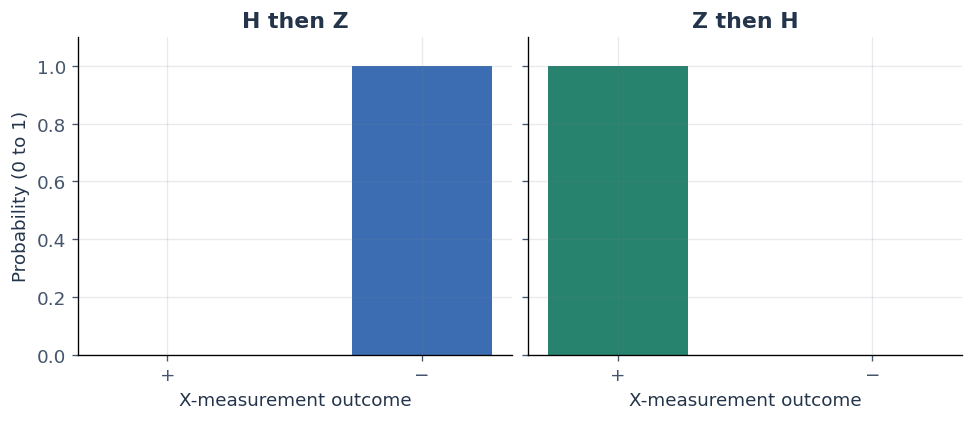

In [5]:
h_then_z = Z @ H @ zero
z_then_h = H @ Z @ zero
print("H then Z amplitudes:", np.round(h_then_z, 6))
print("Z then H amplitudes:", np.round(z_then_h, 6))
print("Commutator ZH - HZ:\n", np.round(Z @ H - H @ Z, 6))
distributions = [probabilities(H @ state) for state in [h_then_z, z_then_h]]
for name, state, x_probs in zip(["H then Z", "Z then H"], [h_then_z, z_then_h], distributions):
    print(f"{name}: Z {np.round(probabilities(state), 6)}, X {np.round(x_probs, 6)}")
assert np.allclose(distributions[0], [0, 1])
assert np.allclose(distributions[1], [1, 0])
fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.4), sharey=True, layout="constrained")
for ax, title, values, color in zip(axes, ["H then Z", "Z then H"], distributions, [BLUE, GREEN]):
    ax.bar(["+", "−"], values, color=color, width=0.55)
    ax.set(title=title, xlabel="X-measurement outcome", ylim=(0, 1.1))
axes[0].set_ylabel("Probability (0 to 1)")
plt.show()

## 6. Recombine amplitudes with H → Rz → H

Start from `|0⟩`, apply H to prepare equal amplitudes, apply `Rz(φ)` to introduce relative phase, and apply H to recombine. In matrix notation the final state is `H @ Rz(φ) @ H @ |0⟩`.

Multiplying the matrices gives the final amplitudes `[cos(φ/2), −i sin(φ/2)]`. Consequently `P(0) = cos²(φ/2) = (1 + cos φ)/2`, and `P(1) = sin²(φ/2)`. These are dimensionless probabilities, not oscillating particle trajectories. Predict the answers at `φ = 0°`, `90°`, and `180°`.

  0°: amplitudes [ 1.+0.j -0.+0.j]; probabilities [1. 0.]
 90°: amplitudes [0.707107-0.j       0.      -0.707107j]; probabilities [0.5 0.5]
180°: amplitudes [0.+0.j 0.-1.j]; probabilities [0. 1.]


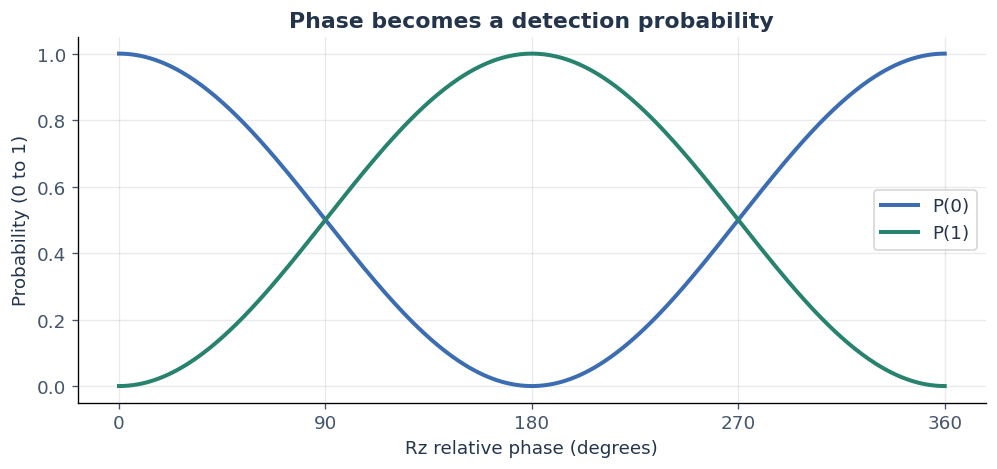

In [6]:
def interference_state(phi):
    return assert_state(H @ Rz(phi) @ H @ zero)


phase_degrees = np.linspace(0, 360, 361)
phase_radians = np.deg2rad(phase_degrees)
predictions = np.array([probabilities(interference_state(phi)) for phi in phase_radians])
assert np.allclose(predictions[:, 0], np.cos(phase_radians / 2) ** 2)
assert np.allclose(predictions.sum(axis=1), 1)
for degrees in [0, 90, 180]:
    state = interference_state(np.deg2rad(degrees))
    print(f"{degrees:3d}°: amplitudes {np.round(state, 6)}; probabilities {np.round(probabilities(state), 6)}")
fig, ax = plt.subplots(layout="constrained")
ax.plot(phase_degrees, predictions[:, 0], color=BLUE, label="P(0)")
ax.plot(phase_degrees, predictions[:, 1], color=GREEN, label="P(1)")
ax.set(xlabel="Rz relative phase (degrees)", ylabel="Probability (0 to 1)",
       xticks=[0, 90, 180, 270, 360], ylim=(-0.05, 1.05), title="Phase becomes a detection probability")
ax.legend()
plt.show()

## 7. See a finite-shot fringe instead of a perfect curve

At each selected phase, prepare a fresh qubit `N = 200` times, run the circuit, and measure Z. The count of outcome `0` is binomial with probability `p = P(0)`. The plotted bars have half-length `sqrt(p(1 − p)/N)`, the model's **one-standard-deviation spread** of estimates over repeated experiments. They are not fitted experimental confidence intervals.

In this ideal model the endpoints have probability exactly one, so sampling variation vanishes there. Real hardware can give incorrect outcomes because of preparation, gate, and readout errors; those errors are outside this notebook's model.

Phase   0°: exact P(0) 1.0000; estimate 1.0000
Phase  30°: exact P(0) 0.9330; estimate 0.9250
Phase  60°: exact P(0) 0.7500; estimate 0.7350
Phase  90°: exact P(0) 0.5000; estimate 0.5200
Phase 120°: exact P(0) 0.2500; estimate 0.2450
Phase 150°: exact P(0) 0.0670; estimate 0.0800
Phase 180°: exact P(0) 0.0000; estimate 0.0000
Phase 210°: exact P(0) 0.0670; estimate 0.0850
Phase 240°: exact P(0) 0.2500; estimate 0.2750
Phase 270°: exact P(0) 0.5000; estimate 0.5250
Phase 300°: exact P(0) 0.7500; estimate 0.6950
Phase 330°: exact P(0) 0.9330; estimate 0.9250
Phase 360°: exact P(0) 1.0000; estimate 1.0000


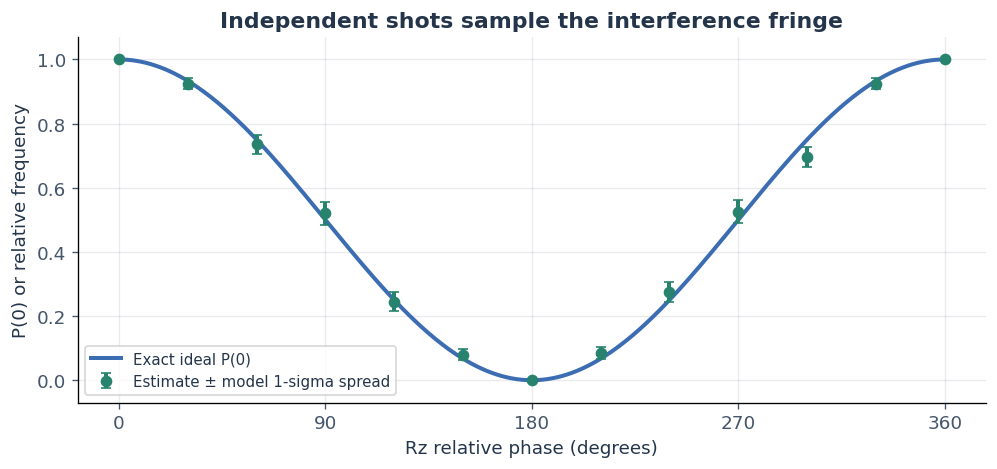

In [7]:
rng = np.random.Generator(np.random.PCG64(20261015))
measured_phases = np.arange(0, 361, 30)
exact_p0 = np.cos(np.deg2rad(measured_phases) / 2) ** 2
shots = 200
counts_zero = np.array([bernoulli_counts(rng, p, shots)[0] for p in exact_p0])
estimates = counts_zero / shots
spreads = np.sqrt(exact_p0 * (1 - exact_p0) / shots)
for phase, exact, estimate in zip(measured_phases, exact_p0, estimates):
    print(f"Phase {phase:3d}°: exact P(0) {exact:.4f}; estimate {estimate:.4f}")
assert counts_zero[0] == shots and counts_zero[-1] == shots
assert counts_zero[6] == 0
fig, ax = plt.subplots(layout="constrained")
ax.plot(phase_degrees, predictions[:, 0], color=BLUE, label="Exact ideal P(0)")
ax.errorbar(measured_phases, estimates, yerr=spreads, fmt="o", color=GREEN, capsize=3,
            label="Estimate ± model 1-sigma spread")
ax.set(xlabel="Rz relative phase (degrees)", ylabel="P(0) or relative frequency", xticks=[0, 90, 180, 270, 360],
       ylim=(-0.07, 1.07), title="Independent shots sample the interference fringe")
ax.legend(fontsize=9)
plt.show()

## 8. Compare coherent amplitudes with a coin mixture

Before the final phase-and-recombination operations, compare two preparations: the coherent state `|+⟩`, and a coin that prepares `|0⟩` on half the runs and `|1⟩` on the other half. Both initially give `[0.5, 0.5]` in Z.

Apply `Rz(φ)` then H to each preparation. For the coin ensemble, calculate each branch's final probabilities separately and average with weights `0.5`. Do **not** average the two state vectors: that would incorrectly create a coherent phase relationship that the preparation does not have.

The coherent input has a fringe. The coin mixture stays at `P(0) = 0.5` because each basis input separately gives fifty-fifty after H, whatever phase is attached to it.

Initial coherent Z probabilities: [0.5 0.5]
Initial mixture Z probabilities: [0.5 0.5]
After Rz(0) then H: coherent P(0) = 1.0 ; mixture P(0) = 0.5


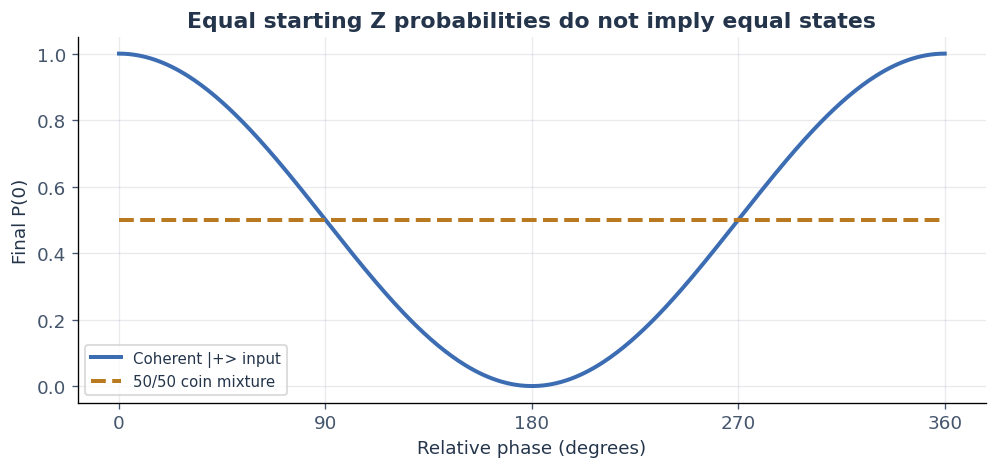

In [8]:
coherent_p0, mixture_p0 = [], []
for phi in phase_radians:
    coherent_p0.append(probabilities(H @ Rz(phi) @ plus)[0])
    branch_zero = probabilities(H @ Rz(phi) @ zero)
    branch_one = probabilities(H @ Rz(phi) @ one)
    mixture_p0.append((0.5 * branch_zero + 0.5 * branch_one)[0])
coherent_p0, mixture_p0 = np.array(coherent_p0), np.array(mixture_p0)
assert np.allclose(coherent_p0, predictions[:, 0])
assert np.allclose(mixture_p0, 0.5)
print("Initial coherent Z probabilities:", np.round(probabilities(plus), 6))
print("Initial mixture Z probabilities:", 0.5 * probabilities(zero) + 0.5 * probabilities(one))
print("After Rz(0) then H: coherent P(0) =", round(coherent_p0[0], 6), "; mixture P(0) =", round(mixture_p0[0], 6))
fig, ax = plt.subplots(layout="constrained")
ax.plot(phase_degrees, coherent_p0, color=BLUE, label="Coherent |+> input")
ax.plot(phase_degrees, mixture_p0, color=AMBER, linestyle="--", label="50/50 coin mixture")
ax.set(xlabel="Relative phase (degrees)", ylabel="Final P(0)", xticks=[0, 90, 180, 270, 360],
       ylim=(-0.05, 1.05), title="Equal starting Z probabilities do not imply equal states")
ax.legend(fontsize=9)
plt.show()

## 9. Reverse a complete circuit

Apply the circuit `U = H @ Rz(φ) @ Ry(θ)` to a new normalized input. Reading from right to left, this means Ry, then Rz, then H. Its inverse is `U† = Ry(−θ) @ Rz(−φ) @ H`: reverse the gate order and invert each gate. The rightmost H is applied first in the inverse.

Predict whether the inverse restores the original amplitudes, not just its Z probabilities. This check concerns **unitary evolution**. It does not mean an unknown measurement result can be universally undone by another gate; measurement discards information differently.

In [9]:
theta, phi = np.deg2rad([75, 40])
input_state = assert_state([np.sqrt(0.3), 1j * np.sqrt(0.7)])
U = H @ Rz(phi) @ Ry(theta)
inverse_by_gates = Ry(-theta) @ Rz(-phi) @ H
output_state = assert_state(U @ input_state)
restored = assert_state(inverse_by_gates @ output_state)
print("Input amplitudes:", np.round(input_state, 6))
print("After Ry → Rz → H:", np.round(output_state, 6))
print("After H → Rz inverse → Ry inverse:", np.round(restored, 6))
print("Maximum restoration error:", f"{np.max(np.abs(restored - input_state)):.3e}")
assert np.allclose(inverse_by_gates, U.conj().T)
assert np.allclose(restored, input_state)
print("All checks passed: unitarity, order, interference, ensemble averaging, and circuit inversion.")

Input amplitudes: [0.547723+0.j      0.      +0.83666j]
After Ry → Rz → H: [0.226581+0.078168j 0.104531-0.965207j]
After H → Rz inverse → Ry inverse: [0.547723+0.j      0.      +0.83666j]
Maximum restoration error: 1.475e-16
All checks passed: unitarity, order, interference, ensemble averaging, and circuit inversion.


**Try a change locally:** change the final H in the interference circuit to the identity. Predict whether sweeping the phase will still change Z probabilities. Then set `φ = 120°` in the original circuit and predict `[P(0), P(1)] = [0.25, 0.75]` before checking.

**Take this with you:** matrices act on amplitudes, gate order matters, and unitarity preserves normalization. Interference needs coherent alternatives and an operation that recombines them. A classical coin ensemble can share a preparation's Z probabilities while behaving differently in another experiment.

Reference: [IBM, Basics of quantum information](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information).